# 3

## (a)
Let $Z = X_{(k)}$. For each $i \in \{1, \ldots, n\}$, define $Z_{-i}$ to be the
$k$-th largest observation among the $n - 1$ values obtained by removing $X_i$.
Since $k \leq n - 1$, $Z_{-i}$ is well defined. By the Efron-Stein inequality,
we know that $Var(Z) \leq \sum_{i = 1}^n E[Var^{(i)}(Z)]$, where $Var^{(i)}(Z) = Var(Z | X_{-i})$
and $X_{-i}$ denotes all observations except $X_i$. Conditionally on $X_{-i}$,
$Z_{-i}$ is a constant because it does not depend on $X_{-i}$. We know that
for any random variable $Y$ and constant $a$:
$$
\begin{align*}
    E[(Y - a)^2] &= E[(Y - EY + EY - a)^2] \\
    &= Var(Y) + (EY - a)^2 \\
    &\geq Var(Y)
\end{align*}
$$
Applying this conditionally with $Y = Z$ and $a = Z_{-i}$, we get $Var^{(i)}(Z) \leq E[(Z - Z_{-i})^2 | X_{-i}]$,
and thus $Var(Z) \leq \sum_{i = 1}^n E[(Z - Z_{-i})^2]$.

Let $\Delta = X_{(k)} - X_{(k + 1)}$. Because observations are ordered in decreasing
order, we know that $\Delta \geq 0$. We need to consider two cases:  
**Case 1**: $X_i$ is among the $k$ largest observations  
Then removing $X_i$ makes the new largest $k$th value become the original $(k + 1)$-th
largest value, so $Z_{-i} = k + 1$, and therefore $Z - Z_{-i} = X_{(k)} - X_{(k + 1)} = \Delta$.  
**Case 2**: $X_i$ is not among the $k$ largest observations  
Then removing $X_i$ does nothing to the $k$ largest observations and $Z - Z_{-i} = 0$.  

Now we sum over all observations with respect to the two cases:
$$
\begin{align*}
    \sum_{i = 1}^n (Z - Z_{-i})^2 &= \underbrace{\Delta^2 + \cdots + \Delta^2}_{k\text{ terms}} + \underbrace{0 + \cdots + 0}_{n-k\text{ terms}} \\
    &= k\Delta^2 \\
    &= k(X_{(k)} - X_{(k+1)})^2 \\
    \sum_{i = 1}^n E[(Z - Z_{-i})^2] &= E[\sum_{i = 1}^n (Z - Z_{-i})^2] \\
    &= kE[(X_{(k)} - X_{(k + 1)})^2] \\
\end{align*}
$$
Then, by Efron-Stein, we finally get:
$$
\begin{align*}
    Var(X_{(k)}) &= Var(Z) \\
    &\leq \sum_{i = 1}^n E[(Z - Z_{-i})^2] \\
    &= kE[(X_{(k)} - X_{(k + 1)})^2]
\end{align*}
$$
Thus, $Var(X_{(k)}) \leq kE[(X_{(k)} - X_{(k + 1)})^2]$ for any $1 \leq k \leq n - 1$.

## (b)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRIALS = 2000
SIZES = [10, 100, 1000, 10000]
BATCH = 200
rng = np.random.default_rng(0)
rows = []

for dist in ('Gaussian', 'Exponential'):
    for n in SIZES:
        measurements = {kname: {'value': [], 'gap2': [], 'jackknife': []}
                        for kname in ('maximum', 'median')}
        for start in range(0, TRIALS, BATCH):
            count = min(BATCH, TRIALS - start)
            if dist == 'Gaussian':
                x = rng.standard_normal((count, n))
            else:
                x = rng.exponential(scale=1.0, size=(count, n))
            for kname, k in (('maximum', 1), ('median', n // 2)):
                p = np.partition(x, (n-k-1, n-k), axis=1)
                xk = p[:, n-k]
                xk1 = p[:, n-k-1]
                gap2 = (xk - xk1)**2
                jackknife = ((n-1)/n) * k * (1-k/n) * gap2
                measurements[kname]['value'].extend(xk.tolist())
                measurements[kname]['gap2'].extend(gap2.tolist())
                measurements[kname]['jackknife'].extend(jackknife.tolist())
        for kname, k in (('maximum', 1), ('median', n // 2)):
            values = np.asarray(measurements[kname]['value'])
            gap2 = np.asarray(measurements[kname]['gap2'])
            jack = np.asarray(measurements[kname]['jackknife'])
            v = values.var(ddof=1)
            b = k * gap2.mean()
            j = jack.mean()
            rows.append({'distribution': dist, 'n': n, 'k': k,
                         'statistic': kname, 'variance': v, 'bound_a': b,
                         'mean_jackknife': j,
                         'relative_sd_jackknife': jack.std(ddof=1)/j,
                         'bound_to_variance': b/v,
                         'jackknife_to_variance': j/v})

df = pd.DataFrame(rows)

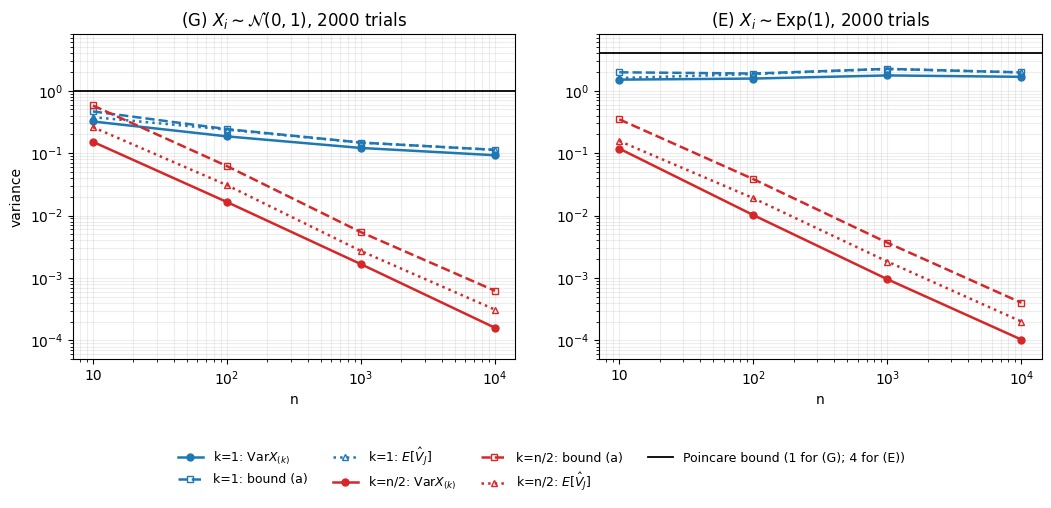

distribution     n    k statistic    variance     bound_a  mean_jackknife  relative_sd_jackknife  bound_to_variance  jackknife_to_variance
    Gaussian    10    1   maximum    0.320902    0.464946        0.376606                1.65096            1.44887                1.17359
    Gaussian    10    5    median    0.151616     0.57883        0.260473                 1.8184            3.81774                1.71798
    Gaussian   100    1   maximum    0.185226    0.242309        0.237487                1.97451            1.30818                1.28215
    Gaussian   100   50    median     0.01647   0.0619844       0.0306823                2.07567            3.76348                1.86292
    Gaussian  1000    1   maximum    0.120886    0.147417        0.147122                1.92604            1.21947                1.21703
    Gaussian  1000  500    median  0.00166544  0.00541575      0.00270517                2.39296            3.25185                 1.6243
    Gaussian 10000    1   m

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0), sharex=True)
colors = {'maximum': 'tab:blue', 'median': 'tab:red'}
style = [('variance', '-', 'o', r'Var$X_{(k)}$'), ('bound_a', '--', 's', 'bound (a)'),
         ('mean_jackknife', ':', '^', r'$E[\hat{V}_J]$')]
for ax, dist in zip(axes, ('Gaussian', 'Exponential')):
    sub = df[df.distribution == dist]
    for kname in ('maximum', 'median'):
        data = sub[sub.statistic == kname]
        for col, ls, marker, label in style:
            ax.plot(data.n, data[col], ls, marker=marker, linewidth=1.8,
                    markersize=5, color=colors[kname],
                    label=f"k={'1' if kname == 'maximum' else 'n/2'}: {label}",
                    markerfacecolor='none' if col != 'variance' else colors[kname])
    pc = 1 if dist == 'Gaussian' else 4
    ax.axhline(pc, color='black', linewidth=1.3, linestyle='-',
               label='Poincare bound (1 for (G); 4 for (E))')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xticks(SIZES, ['10', r'10$^2$', r'10$^3$', r'10$^4$'])
    if dist == 'Gaussian':
        ax.set_title(r'(G) $X_i \sim \mathcal{N}(0, 1)$' + f', {TRIALS} trials')
    else:
        ax.set_title(r'(E) $X_i \sim \mathrm{Exp}(1)$' + f', {TRIALS} trials')
    ax.set_xlabel('n')
    ax.grid(True, which='both', alpha=0.22)
    ax.set_ylim(5e-5, 8)
axes[0].set_ylabel('variance')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.06),
           ncol=4, fontsize=9, frameon=False)
fig.subplots_adjust(bottom=0.23, wspace=0.19)
plt.show()

print(df.to_string(index=False, float_format=lambda z: f'{z:.6g}'))

i.  
**Gaussian max**: Variance decreases slowly as $n$ increases at a rate of $\frac{1}{\log n}$.
Both bound (a) and the expected jackknife follow the same order of decrease. Poincare
bound remains constant at 1.  
**Gaussian median**: Variance decreases slowly as $n$ increases at a rate of around $\frac{1}{n}$.
Both bound (a) an the expected jackknife follow the same order of decrease but overestimate
the variance.  
**Exponential max**: Variance approaches a positive constant rather than decreasing 
to zero. Bound (a) and the expected jackknife approach 2, so they have the correct 
constant-order dependence.  
**Exponential median**:  Variance decreases slowly as $n$ increases at a rate of around $\frac{1}{n}$.
Both bound (a) an the expected jackknife follow the same order of decrease.  
The Poincare bound doesn't capture these rates because for the $k$-th largest
order statistic, $f(x) = x_{(k)}$. Whenever all coordinates are distinct, exactly
one coordinate determines the $k$-th largest value. Hence, the gradient only
has one entry equal to 1 and all other entries are equal to 0. Therefore, $\|\nabla f(x)\|_2^2 = 1$
almost everywhere, giving $E[\|\nabla f(X)\|_2^2] = 1$, and any upper bound of 
the form $CE[\nabla f(X)\|_2^2] = C$ is constant in $n$. Consequently, it can't
capture the decreasing value for either median or max Gaussian.  

ii. At $n = 10,000$:
| Distribution | $k$ | Bound (a) factor | Jackknife factor
|-|-|-|-|
| Gaussian | 1 | 1.22x | 1.22x |
| Gaussian | 5,000 | 3.91x | 1.96x |
| Exponential | 1 | 1.18x | 1.18x |
| Exponential | 5,000 | 3.89x | 1.95x |

We can see that bound (a) overestimates by around 20% for $k = 1$ and 4 times for
$k = 5,000$ while jackknife overestimates  by around also 20% for $k = 1$ but only
2 times for $k = 5,000$.

iii. No, the simulation indicates that the ratio goes to around 2. For exponential
order statistics, the adjacent spacing satisfies $\Delta = X_{(k)} - X_{(k + 1)} \sim \text{Exp}(k)$.
We already know that the jackknife is a constant multiple of $\Delta^2$, so its
relative standard deviation also equals that of $\Delta^2$. For an exponential 
random variable with rate $k$, $E[\Delta^2] = \frac{2}{k^2}$, $E[\Delta^4] = \frac{24}{k^4}$.
Consequently, $Var(\Delta^2) = E[\Delta^4] - (E[\Delta^2])^2 = \frac{24}{k^4} - \frac{4}{k^4} = \frac{20}{k^4}$.
Therefore, the ratio is now equal to $\frac{\sqrt{20/k^4}}{2/k^2} = \sqrt{5} \sim 2.2$.
Thus, for exponential observations, the jackknife's relative standard deviation 
is exactly $\sqrt{5}$ for every sample size and every eligible $k$. The Gaussian 
results are also consistent with this, because the appropriately rescaled adjacent 
order-statistic gaps approach exponential distributions.

No, we should not use the jackknife to estimate the variance of a sample median
since it is unreliable for estimating variance. Its expected value is approximately
twice the actual median variance in the simulation, so it has substantial upward bias.
Second, its relative standard deviation does not approach zero. Even with a very
large sample, one observed adjacent spacing can produce a highly variable variance
estimate.